#Goggle drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Import

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import matplotlib.font_manager as fm

#Read csv file

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/dataset/kospi200_cleaned_data.csv')
df

,y,m,d,closing price,market price,high price,low price,volume_M,change
0,2024,12,30,317.82,318.13,322.20,316.94,73.58,-0.38
1,2024,12,27,319.03,320.24,321.30,316.91,86.74,-0.75
2,2024,12,26,321.45,324.48,324.48,321.42,92.61,-0.60
3,2024,12,24,323.39,324.11,324.50,321.86,78.51,0.13
4,2024,12,23,322.98,321.00,324.00,319.77,100.61,1.46
...,...,...,...,...,...,...,...,...,...
713,2022,2,7,362.92,365.40,365.40,359.59,135.53,-0.93
714,2022,2,4,366.34,363.10,366.79,361.84,109.79,1.31
715,2022,2,3,361.60,364.07,366.13,361.60,125.48,1.01
716,2022,1,28,357.98,350.29,358.84,347.28,146.98,2.70


In [ ]:
df['ymd'] = pd.to_datetime(df['y'].astype(str) + '-' + df['m'].astype(str) + '-' + df['d'].astype(str))

In [ ]:
df.drop(['y', 'm', 'd'], axis=1, inplace=True)
df

,closing price,market price,high price,low price,volume_M,change,ymd
0,317.82,318.13,322.20,316.94,73.58,-0.38,2024-12-30
1,319.03,320.24,321.30,316.91,86.74,-0.75,2024-12-27
2,321.45,324.48,324.48,321.42,92.61,-0.60,2024-12-26
3,323.39,324.11,324.50,321.86,78.51,0.13,2024-12-24
4,322.98,321.00,324.00,319.77,100.61,1.46,2024-12-23
...,...,...,...,...,...,...,...
713,362.92,365.40,365.40,359.59,135.53,-0.93,2022-02-07
714,366.34,363.10,366.79,361.84,109.79,1.31,2022-02-04
715,361.60,364.07,366.13,361.60,125.48,1.01,2022-02-03
716,357.98,350.29,358.84,347.28,146.98,2.70,2022-01-28


#Identified colume

In [ ]:
price_columns = ['closing price', 'market price', 'high price', 'low price']
colors = ['blue', 'green', 'red', 'purple']
df_long = df.melt(id_vars=['ymd'], value_vars=price_columns, var_name='Price Type', value_name='Price')
plt.figure(figsize=(15, 7))

<Figure size 1500x700 with 0 Axes>

<Figure size 1500x700 with 0 Axes>

#Closing price, Market price, High price, Low price visualzation

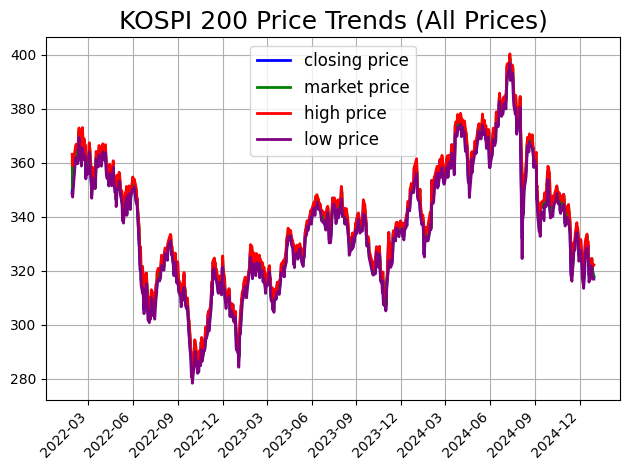

In [ ]:
for i, col in enumerate(price_columns):
    plt.plot(df['ymd'], df[col], label=col, color=colors[i], linewidth=2)
plt.title('KOSPI 200 Price Trends (All Prices)', fontsize=18)
plt.legend(fontsize=12)
plt.grid(True)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)) # 3개월 간격으로
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45, ha='right', fontsize=10) # 45도 기울기

plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

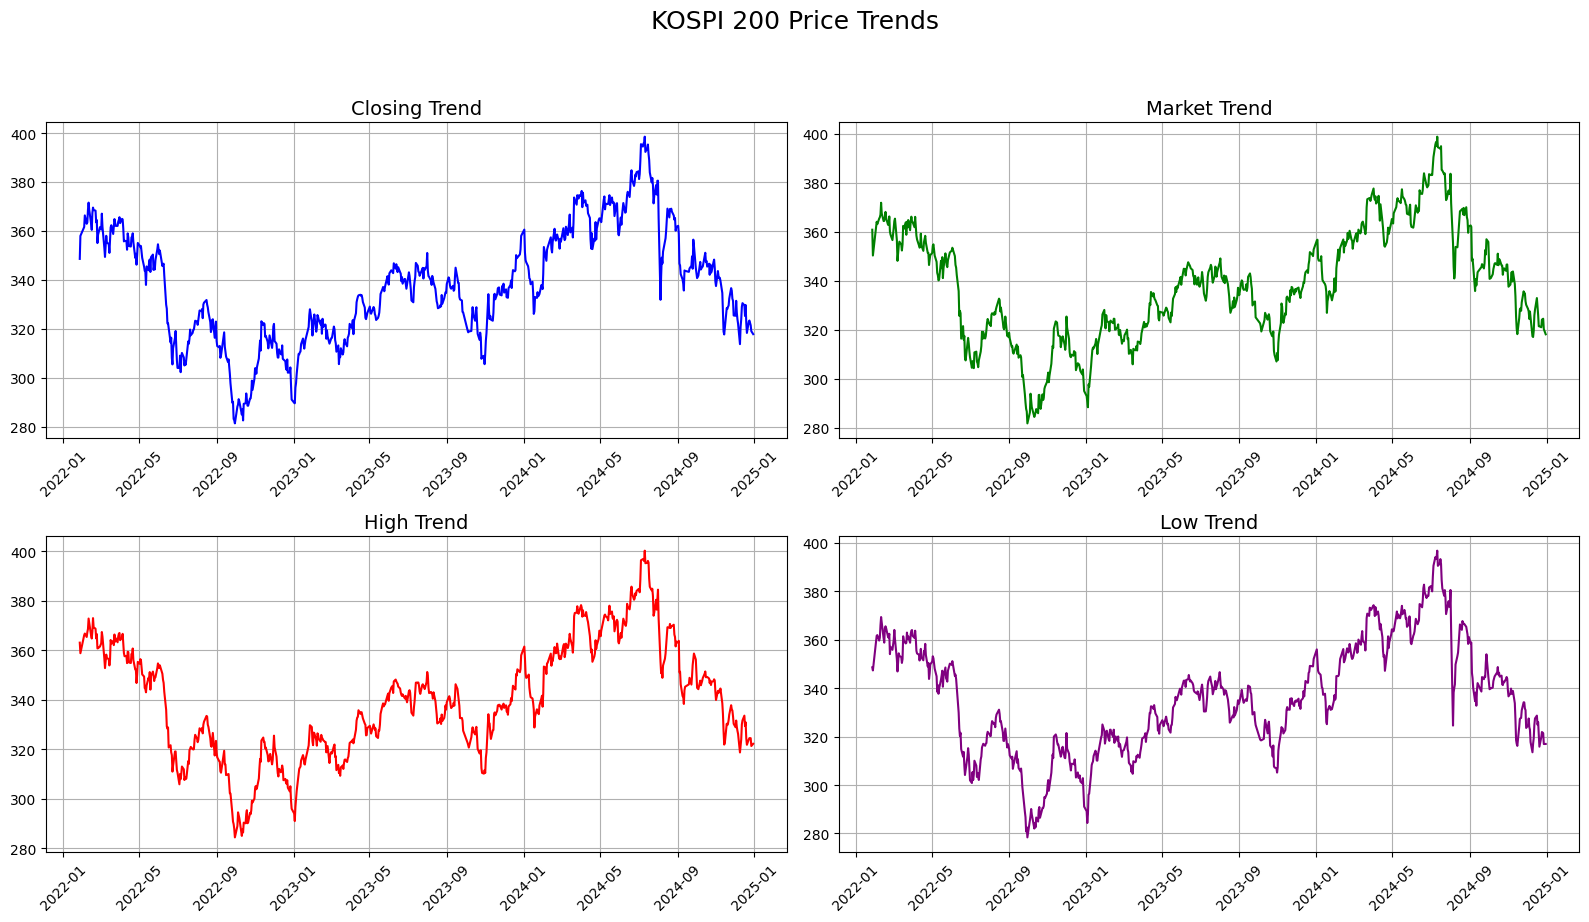

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(price_columns):
    ax = axes[i]
    ax.plot(df['ymd'], df[col], label=col, color=colors[i])
    ax.set_title(f'{col.replace(" price", "").title()} Trend', fontsize=14)
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('KOSPI 200 Price Trends', fontsize=18, y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

#Volume data visualzation

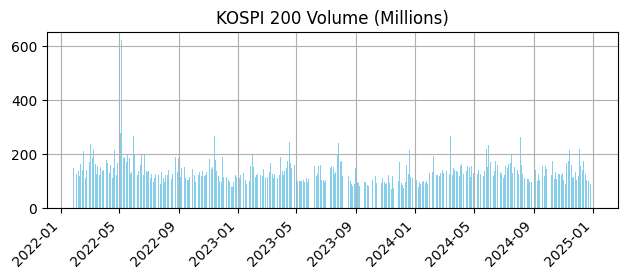

In [ ]:
plt.subplot(2, 1, 2)
plt.bar(df['ymd'], df['volume_M'], color='skyblue', width=0.9)
plt.title('KOSPI 200 Volume (Millions)')
plt.grid(True)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
df_volume = df[['volume_M', 'ymd']]
volumes_ymd = df_volume.sort_values(by='volume_M', ascending=False).head(10)
volumes_ymd

,volume_M,ymd
652,622.95,2022-05-06
676,446.85,2022-04-01
677,388.61,2022-03-31
418,298.77,2023-04-14
349,296.54,2023-07-26
653,279.18,2022-05-04
532,272.49,2022-11-01
109,269.87,2024-07-18
523,267.59,2022-11-14
635,266.68,2022-05-31


from matplotlib import pyplot as plt
volumes_ymd['volume_M'].plot(kind='hist', bins=20, title='volume_M')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  xs = series['ymd']
  ys = series['volume_M']
  
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = volumes_ymd.sort_values('ymd', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('ymd')
_ = plt.ylabel('volume_M')

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['ymd']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'ymd'}, axis=1)
              .sort_values('ymd', ascending=True))
  xs = counted['ymd']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = volumes_ymd.sort_values('ymd', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('ymd')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
volumes_ymd['volume_M'].plot(kind='line', figsize=(8, 4), title='volume_M')
plt.gca().spines[['top', 'right']].set_visible(False)

#Change data visualzation

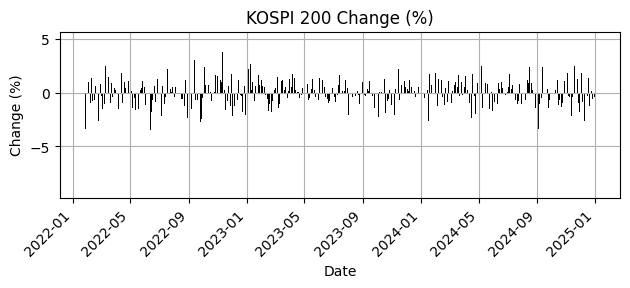

In [ ]:
plt.subplot(2, 1, 2)
plt.bar(df['ymd'], df['change'], color='black', width=0.9)
plt.title('KOSPI 200 Change (%)')
plt.xlabel('Date')
plt.ylabel('Change (%)')
plt.grid(True)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
df_change = df[['change', 'ymd']]
abs_change = df_change.sort_values(by='change', key=abs, ascending=False).head(10)
abs_change

,change,ymd
97,-9.12,2024-08-05
282,5.00,2023-11-06
98,-4.04,2024-08-02
524,3.84,2022-11-11
628,-3.51,2022-06-13
63,3.45,2024-09-26
717,-3.39,2022-01-27
76,-3.38,2024-09-04
221,3.22,2024-02-02
565,3.05,2022-09-13


#Check out news stories where stock prices soar, fall sharply

**abs : absolute value [ 절댓값 ]**

In [ ]:
df['abs_change'] = df['change'].abs()
df_sorted_change = df.sort_values(by='abs_change', ascending=False)

**.to_markdown : Converting data to a table string in markdown format to pandas or dataframe, Make the result look pretty**

In [ ]:
filtered_df = df[df['abs_change'] >= 2]
print(filtered_df[['ymd', 'change', 'abs_change']].to_markdown(index=False))

| ymd                 |   change |   abs_change |
|:--------------------|---------:|-------------:|
| 2024-12-19 00:00:00 |    -2.23 |         2.23 |
| 2024-12-10 00:00:00 |     2.25 |         2.25 |
| 2024-12-09 00:00:00 |    -2.59 |         2.59 |
| 2024-11-18 00:00:00 |     2.47 |         2.47 |
| 2024-11-13 00:00:00 |    -2.59 |         2.59 |
| 2024-11-12 00:00:00 |    -2.19 |         2.19 |
| 2024-09-30 00:00:00 |    -2.59 |         2.59 |
| 2024-09-26 00:00:00 |     3.45 |         3.45 |
| 2024-09-12 00:00:00 |     2.44 |         2.44 |
| 2024-09-04 00:00:00 |    -3.38 |         3.38 |
| 2024-08-16 00:00:00 |     2.42 |         2.42 |
| 2024-08-07 00:00:00 |     2.15 |         2.15 |
| 2024-08-06 00:00:00 |     2.97 |         2.97 |
| 2024-08-05 00:00:00 |    -9.12 |         9.12 |
| 2024-08-02 00:00:00 |    -4.04 |         4.04 |
| 2024-06-03 00:00:00 |     2.03 |         2.03 |
| 2024-05-07 00:00:00 |     2.54 |         2.54 |
| 2024-04-24 00:00:00 |     2.14 |         2.14 |


**2023**

2023.11.15

- 코스피, '에코프로비엠' 강세에 상승 마감

- 외국인·기관 매도세에도 개인 '사자'... 코스피 2,470선 강보합

- 2차전지 반등에 코스피 소폭 상승, 코스닥 0.35%↑

- LG전자 주가, 52주 신저가 경신에 관심

- 한화에어로스페이스, 우주 사업 기대감에 상승

2023.11.07

- 코스피, 기관 매도세에 하락 마감... 2,420선 '털썩'

- 미국 금리인상 우려에 코스피 하락, 코스닥도 약세

- 네이버, 고점 대비 반토막... 주가 하락세 지속

- 에코프로 그룹주, 2차전지 약세에 하락

- 반도체주 약세 지속... 삼성전자, SK하이닉스 하락

2023.11.06

- 코스피, 외국인·기관 순매수에 상승 마감... 2,430선 회복

- 카카오, 실적 개선 기대감에 상승세

- 바이오주 강세... 셀트리온, 삼성바이오로직스 상승

- 미국 기술주 랠리 영향에 국내 증시 상승

- 원·달러 환율, 소폭 하락하며 1,300원대 중반 기록

2023.10.26

- 코스피, 2,300선 깨졌다... 1년 만에 최저치

- 외국인·기관 '팔자'... 코스피 2,300선 붕괴

- 미국 긴축 장기화 우려에 국내 증시 폭락

- 2차전지주, 급락세 지속... 에코프로비엠 하한가

- 고금리·고환율에 투자심리 위축... 증시 약세

2023.10.04

- 코스피, 2,400선 아래로... 외국인·기관 순매도

- 미국 국채금리 급등에 국내 증시 하락

- 환율, 1,350원 돌파... 고환율 압박 지속

- 건설주, 부동산 PF 우려에 약세

- 항공주, 유가 상승에 하락세

2023.08.02

- 코스피, 외국인·기관 순매도에 하락 마감... 2,600선 하회

- 2차전지株 하락세... 에코프로 그룹주 약세

- 미국 신용등급 강등 여파에 글로벌 증시 불안

- 반도체주도 약세... 삼성전자, SK하이닉스 하락

- 원·달러 환율, 소폭 상승하며 1,280원대 기록

2023.03.14

- 코스피, 美은행 파산 여파에 급락... 2,350선 '와르르'

- SVB 파산 후폭풍... 국내 금융주 하락

- 비트코인, 금융 불안에 급락세

- 외국인 대규모 매도... 코스피 2% 이상 하락

- 경기 침체 우려 확산... 증시 불확실성 증대

2023.02.06

- 코스피, 외국인 매도세에 하락 전환... 2,450선 마감

- 테슬라 급등에 2차전지주 동반 상승 기대감

- 항공주, 리오프닝 기대감에 상승

- 조선주, 수주 증가 기대감에 상승세

- 외국인, 삼성전자 '사자'... SK하이닉스 '팔자' 엇갈려

2023.01.09

- 코스피, 외국인 순매수에 상승 마감... 2,350선 회복

- 중국 리오프닝 기대감에 소비주 강세

- 항공주, 여행 수요 회복 기대감에 상승

- 기관, 반도체주 집중 매수... 삼성전자, SK하이닉스 상승

- 원·달러 환율, 소폭 하락하며 1,250원대 기록

2023.01.04

- 코스피, 외국인 매수세에 상승 마감... 2,260선 안착

- 연초 증시 랠리 기대감... 개인 '사자'

- 반도체주 상승... 삼성전자, SK하이닉스 강세

- 중국 리오프닝 기대감에 화장품·면세점 관련주 상승

- 자동차주, 신차 판매 호조에 상승세


**2022**

2022.12.29

- 코스피, 올해 마지막 거래일 하락 마감... 2,230선 턱걸이

- 기관 매도세에 코스피 약세... 연말 북클로징 영향

- 카카오뱅크, 52주 신저가 경신... 주가 부진 지속

- 포스코홀딩스, 실적 악화 우려에 하락

- 배터리 관련주, 전기차 판매 둔화 우려에 하락

2022.12.28

- 코스피, 외국인 순매수에 상승 마감... 2,280선 회복

- 반도체주 상승... 삼성전자, SK하이닉스 강세

- 중국 방역 완화 기대감에 소비주 상승

- 원·달러 환율, 소폭 하락하며 1,270원대 기록

- 셀트리온, 신약 개발 기대감에 상승

2022.12.02

- 코스피, 외국인 매도에 하락 마감... 2,420선 '털썩'

- 화물연대 파업 장기화 우려에 물류 관련주 하락

- 건설주, 부동산 경기 침체 우려에 약세

- 정부, 화물연대 파업 강경 대응 방침... 관련주 희비

- 물가 상승 압박 지속... 금리 인상 가능성

2022.11.11

- 코스피, 미국 CPI 둔화에 급등... 2,480선 안착

- 미국 인플레이션 완화 기대감에 증시 랠리

- 반도체주 강세... 삼성전자, SK하이닉스 폭등

- 성장주 급등... 네이버, 카카오 등 상승

- 외국인, 대규모 순매수... 코스피 상승 견인

2022.10.14

- 코스피, 외국인·기관 매도에 하락 마감... 2,200선 위협

- 미국 인플레이션 지표 발표 앞두고 관망세

- 환율, 1,440원대 재진입... 고환율 압박 지속

- 건설주, 부동산 PF 우려에 하락

- 항공주, 유가 상승 부담에 약세

2022.10.04

- 코스피, 북한 미사일 도발에 하락 출발... 2,200선 붕괴

- 지정학적 리스크 고조에 투자심리 위축

- 외국인 대규모 매도... 코스피 약세

- 코스닥도 하락... 2차전지주 약세

- 방산주, 미사일 도발에 상승세

2022.09.28

- 코스피, 2,200선 붕괴... 2020년 7월 이후 최저치

- 미국 금리 인상 속도 우려에 국내 증시 폭락

- 환율 1,440원 돌파... 강달러 현상 심화

- IT 대형주 약세... 삼성전자, SK하이닉스 하락

- 경기 침체 우려 확산... 증시 약세 지속

2022.09.26

- 코스피, 2,300선 깨졌다... 외국인·기관 순매도

- 글로벌 경기 침체 우려에 증시 약세

- 테슬라 주가 하락에 2차전지주 동반 하락

- 원·달러 환율, 급등하며 1,430원대 기록

- 증시 변동성 확대... 투자자 불안감 증폭

2022.09.13

- 코스피, 미국 CPI 발표 앞두고 혼조세... 2,400선 등락

- 개인 매수세에 코스피 강보합

- 반도체주 강세... 삼성전자, SK하이닉스 상승

- 항공주, 리오프닝 기대감에 상승

- 해운주, 운임 하락 우려에 하락세

2022.09.01

- 코스피, 외국인·기관 순매수에 상승 마감... 2,400선 회복

- 경기 침체 우려 완화에 투자심리 개선

- 태풍 힌남노 피해 우려에 건설·보험 관련주 하락

- 에너지 관련주, 유가 하락에 약세

- 제약·바이오주 강세... HLB, 셀트리온 상승

2022.08.29

- 코스피, 2,420선 등락... 외국인·기관 순매도

- 잭슨홀 미팅 이후 긴축 강화 우려에 증시 약세

- 기술주 약세... 네이버, 카카오 하락

- 환율 1,340원대 진입... 강달러 현상 지속

- 전기차 관련주, 완성차 판매 부진 우려에 하락

2022.07.18

- 코스피, 외국인 매도세에 하락 마감... 2,300선 '털썩'

- 글로벌 경기 침체 우려에 투자심리 위축

- 반도체주 약세... 삼성전자, SK하이닉스 하락

- 항공주, 유가 상승에 하락세

- 여행·레저 관련주, 코로나 재확산 우려에 하락

2022.07.06

- 코스피, 외국인 순매수에 상승 마감... 2,320선 회복

- 경기 침체 우려 완화에 증시 반등

- 자동차주 강세... 현대차, 기아 상승

- 철강주, 중국 봉쇄 완화 기대감에 상승

- 원·달러 환율, 소폭 하락하며 1,290원대 기록

2022.06.24

- 코스피, 외국인 매도에 하락 마감... 2,340선 위태

- 금리 인상 및 경기 침체 우려에 투자심리 위축

- 반도체주 약세 지속... 삼성전자, SK하이닉스 하락

- 2차전지주, 급락세 지속... LG에너지솔루션 하한가

- 미국 증시 약세 영향에 국내 증시도 하락

2022.06.22

- 코스피, 2,400선 등락... 외국인 매도세 지속

- 환율 1,300원 돌파... 고환율 압박 가중

- 항공주, 유가 상승 부담에 하락

- 조선주, 해운업 침체 우려에 하락

- IT 대형주 약세... 카카오, 네이버 하락

2022.06.13

- 코스피, '블랙먼데이' 기록... 2,500선 붕괴

- 미국 CPI 쇼크에 글로벌 증시 폭락

- 외국인, 대규모 매도... 코스피 급락

- 카카오뱅크, 52주 신저가 경신... 인터넷은행주 약세

- 증시 불안감 최고조... 투자자들 패닉셀링

2022.05.13

- 코스피, 2,600선 하회... 외국인·기관 순매도

- 미국 긴축 가속화 우려에 국내 증시 약세

- 원·달러 환율, 1,280원 돌파... 고환율 압박 지속

- 기술주 약세... 네이버, 카카오 하락

- 카카오페이, 52주 신저가 경신... 핀테크주 부진

2022.03.10

- 코스피, 대선 결과 안도감에 상승... 2,680선 회복

- 윤석열 당선에 정책 기대감... 건설주, 원전주 강세

- 기관 매수세 유입... 코스피 상승 견인

- 제약·바이오주 약세... 셀트리온 하락

- 러시아-우크라이나 전쟁 장기화 우려에 유가 급등

2022.03.07

- 코스피, 러시아-우크라이나 전쟁 장기화에 하락... 2,650선 마감

- 국제 유가 폭등에 인플레이션 우려 고조

- 외국인 매도세 지속... 국내 증시 약세

- 항공주, 유가 부담에 하락

- 증권주, 증시 불확실성 증대에 하락

2022.02.24

- 코스피, 러시아-우크라이나 전쟁 발발에 급락... 2,640선 붕괴

- 러시아, 우크라이나 전면 침공... 글로벌 증시 패닉

- 유가 급등 및 원자재 가격 상승... 인플레이션 우려

- 외국인, 대규모 매도... 코스피 폭락

- 방산주, 전쟁 발발에 상승세

2022.01.28

- 코스피, 설 연휴 앞두고 2,600선 붕괴... 기관 매도세

- 오미크론 확산 및 인플레이션 우려에 증시 약세

- 삼성전자, 실적 발표 앞두고 하락

- 카카오페이, 공모가 하회... 핀테크주 부진

- 셀트리온, 신약 개발 불확실성 확대에 하락

2022.01.27

- 코스피, 외국인 매도세에 하락... 2,700선 '털썩'

- 미국 연준 긴축 강화 시사에 투자심리 위축

- LG에너지솔루션 상장 첫날 급등락... '따상' 실패

- 반도체주 약세... 삼성전자, SK하이닉스 하락

- 카카오, 실적 부진 우려에 하락

2024.12.19

- 환율 1,450원 돌파, 외국인·기관 현/선물 1조 원 이상 매도 → 코스피200 하방 압력

- FOMC '매파' 기조 충격으로 야간 선물·옵션 지수 약 1.5–2.2% 급락

- 장중 코스피 2,400선 붕괴, 2,436 마감

- 외국인·기관 주도 매도 속 개인만 저가 매수 (8,000억원 규모)

- 정치 불안·환차손 우려 → 외국인 이탈 가속화, 수출주는 강세

2024.12.10

- [2024 증시결산] 코스피 올해 10% 급락, 코스닥 22% 추락 (코스피 200 포함 대형주 부진 시사)

- 안전자산 선호 심화 → IPO·ETF 횡보, 코스피 200 종목 등 대형주 거래 집중

- 정치적 불확실성 유입으로 KOSPI 2,450선 이탈, Worst Case 현실화 가능성 확대 경고

- 최근 10년 국내 증시 수익성 저조 언급

- 외국인 8조 순매수, 반도체 대형주 주도 (KCIF 보고서)

2024.12.09

- (해당 날짜에 대한 코스피 200에 직접적인 영향을 미칠만한 주식 시장 기사는 확인되지 않습니다.)

2024.11.18

- 삼성전자 자사주 이미지로 13% 이상 상승 언급, 코스피 200 지수 상승에 큰 영향

- KB 리포트: 美 증시 약세·연준 긴축 우려, 대형주 점검 필요

- 트럼프 2기 자율주행 규제 완화 기대 → 라이다 등 테마주 부각 (관련 대형주 있다면 코스피 200 영향)

- HLB제약 등 특정 테마 관련주 급등 (코스피 200 구성 종목 중 관련 대형주 움직임 가능성)

- 삼성전자, 현대차 조합의 지수 견인 역할 언급 (개인 블로그 형태의 시황 분석)

2024.11.13

- 코스피·코스닥 동반 하락, 삼성전자 5만원 선 위협 (대형주 약세가 코스피 200 하락의 주요 원인)

- 외국인·기관 각각 대규모 순매도 → 코스피 2,500선 붕괴 압력

- 트럼프 쇼크에 증시 폭락, 성장률 하향, 역대급 환율 → 거시 경제 악화 및 해외 변수 영향

- 코스피 석 달 만에 2,500선 무너짐 (코스피 200에 직접적 영향)

- 거래량 감소 → 유동성 부족, 대형주 자금 이탈 가속

2024.11.12

- (해당 날짜에 대한 코스피 200에 직접적인 영향을 미칠만한 주식 시장 기사는 확인되지 않습니다.)

2024.09.30

- ‘코리아 밸류업 지수’ 출시 첫날 –2.8%, 코스피200(–2.59%)보다 더 급락

- 코스피 지수 –2.13% 하락, 외국인·기관 동반 매도세 확대

- 5년째 ‘9월 징크스’로 2,600선 붕괴 → 기술·수출주 약세

- 외국인 1.7조 순매수 급등세 → SK하이닉스 중심 반도체 강세 나타남

- 미국발 경기 침체 우려·파월 발언 대기감으로 글로벌 증시장 변동성 확대

2024.09.26

- 외국인, 코스피200 선물 1.24조 및 현물 4,890억 동반 순매수 → 지수 +2.9% 급등

- SK하이닉스 9.4%↑ 및 삼성전자 4%↑ → 외국인 매수 주도 대형주 강세

- 마이크론 실적 호조 → 글로벌 반도체 업종 분위기 반전

- 기관도 대형주 동반 매수, 개인은 매도 우위로 역할 교체 양상

- 외국인 선물매수 주중 지속, 코스피200 지수 방향성에 중심축 역할

2024.09.12

- (해당 날짜에 대한 코스피 200에 직접적인 영향을 미칠만한 주식 시장 기사는 확인되지 않습니다.)

2024.09.04

- Eurex KOSPI200 선물 –2.31% 폭락, 미 증시 연계 급락 여파

- 글로벌 증시 동반 약세 → 미국 S&P500 –2.12%, 나스닥 –3.26% 등 변동성 확대

- 채권·유가 급락 → 경기 둔화 우려 심화, 증시 리스크 확대

- 외국인·기관 매도, 개인·연기금 분할 대응 보이는 혼조 장세

- "미국발 악재에 코스피 2,600 붕괴" 시황 보도

2024.08.16

- 미국의 야간(overnight) 주식시장 변화 시사점 (해외 증시 동향이 코스피 200에 간접적 영향)

2024.08.07

- 뉴욕증시 하루 만에 반등 소식에 코스피 +3% 급등

- 개인 매수·외국인 코스피200 선물 순매수 주도

- 삼성전자 HBM 이슈 부각 → 시가총액 대형 기술주 강세

- SK하이닉스 소폭 조정, 기술주 간 업종별 희비 교차 장세

- 외국인, 현물 매도 → 선물 매수 패턴 나타남, 기관은 관망세

2024.08.06

- 코스피 전날 ‘블랙 먼데이’ 후 패닉셀 완화, 하루 만에 급반등

- 외국인·기관 동시 매도 → 코스피와 코스닥 역사적 낙폭 기록

- 한국거래소는 동시 사이드카·서킷브레이커 발동 → 시장 변동성 극대화

- 유동성 급변 → 투자자 주의보, ‘불안정 여전’ 메시지 공유

- 시황 분석 “전강·후약”으로 글로벌 변동성 경계 강조

2024.08.05

- 코스피 블랙 먼데이 재현, 2,440대 장중 붕괴 → 코스피200 포함 대부분 종목 동반 급락

- 98% 종목 하락, 반도체·2차전지 중심 대형주 급락 도미노

- 서킷브레이커·사이드카 동시 발동, 시장 극심 혼란

- 공포 지수 뛴 가운데 삼성전자·SK하이닉스 5% 이상 하락

- 외국인 대량 매도 → ETF·코스피200 대표 지수 심리 위축

2024.08.02

- 코스피 장중 2.9% 급락, 2,700선 붕괴 → 코스피200 포함 시장 전반 약세

- 모든 업종 동반 약세, 외국인·기관 동반 매도

- 코로나19 재확산 → 진단키트주 급등 (전체 시장 영향은 미미)

- 세계 증시 동반 급락 (미국·유럽 2~3% 하락) 영향

- 투자자들 “코리아 리스크 확산” 우려 증가

2024.06.03

- 대통령 선거일, 증시 휴장 (주식·파생·채권시장 전면 휴장)

- 한국거래소 휴장으로 인해 코스피200 지수 산출 중단

- 휴장일 영향 → 투자심리·유동성 일시 정체

- 당일 외국인·기관 직접 매매 불가로 거래 구조 안정

- 정부, 휴장 통한 시장 안정 효과 기대

2024.05.07

- KCIF 전망: 금리 급등·통화긴축 장기화로 상반기 상승폭 일부 반납 필요 (코스피 200 지수 중장기 전망)

- 외국인, 올 들어 코스피 +8.2조 순매수 → 코스피200 대형주 주도

- 반도체 중심 매수세 유입, SK하이닉스·삼성전자 강세 지속

- 주요 IB 연말 목표지수 2,670~2,800 제시 → 시장 기대 감지

- 대형주 선호 현상 → 코스피200 구성 종목 중심으로 자금 유입

2024.04.24

- 코스피 상반기 강세, 하반기 블랙먼데이 후 2,399.49로 마감 (코스피 200 포함 지수 전반의 하락 마감 추세)

- 코스피 4거래일 연속 하락 → 코스피200에도 지속 하방압력

- 상반기 밸류업 프로그램 모멘텀에 상승; 하반기 블랙먼데이·국내외 정치 리스크 등에 하락세 전환

- 연말 전망 악화 → 기관 보수적 모드 전환·포지션 축소

- 수출주 약세 → 코스피200 포함 수출 대형주 부진 지속

2024.04.16

- 삼성증권, 금융·배당 매력 부각, 금융주 코스피200 일부 종목 강세

- 증시 일일 거래대금 23.6조 기록 → 시장 유동성 증가 영향 (코스피 200에도 긍정적 영향)

- 유동성 증가로 코스피200 내 은행·보험 등 금융섹터 강세 주도

- 기관·외국인 매수 러시 → 금융·에너지 대형주 중심 수익률 개선

- 단기적으로 코스피200 거래 활성화에 긍정적

2024.03.21

- 주식거래 시간 연장 (8시~20시) 시행 → 거래량 증가 기대 (장기적으로 코스피 200에도 영향)

- 거래시간 확대, 해외 시간대 연계 투자 여건 개선 → 대형주 수급 변화 기대

- 코스피 2500선 무너짐 (반도체주 힘 못 쓰고 삼성전자 53,000원까지 밀림) (코스피 200에 직접적 영향)

- 해외 발 악재 → 코스피 2500 붕괴 위험 지속 경고 (거시 경제 및 대외 변수가 국내 증시 전반, 특히 코스피 200 대형주에 미치는 영향)

- 대형 반도체주 삼성전자, SK하이닉스, 분할 매매 확대 움직임

2024.02.02

- [2024 증시결산] 밸류업 중심 주가 상승, 트럼프 불확실성 충격 (코스피 200 포함 저평가 대형주 정책 기대감)

- 윤석열 대통령, '코리아 디스카운트' 해소 공언 → 정부 정책 기조가 코스피 200 포함 국내 증시 전반에 긍정적 기대감 형성

- 밸류업 정책 윤곽 드러나며 시장 관심 집중 (주요 대형주(코스피 200 구성 종목)의 가치 상승 기대감 유발)

- 외국인 투자자, 2월에만 7조7천9백11억원 순매수하며 밸류업에 기대 (외국인 대규모 순매수가 코스피 200 포함 대형주에 직접적인 상승 동력)

- 정책 모멘텀 강화 → 대형주 배당, 가치주 중심 포지션 확대

2024.01.17

- 윤 대통령, 한국거래소 방문 및 금융 주제 민생 토론회 개최 (금투세 폐지 방침 등) → 정부의 증시 부양 의지 표명은 코스피 200 포함 시장 전반에 긍정적 기대감 형성

- 높아지는 北 위협…美 핵항모 전개, 제주 인근서 한미일 연합훈련 (지정학적 리스크 영향, 관련 대형 방산주 코스피 200에 간접적 영향)

- '반도체 생명수' 초순수 국산화, 8월부터 웨이퍼 생산 첫 사용 (반도체 산업 관련 긍정적 뉴스가 코스피 200 내 반도체 대형주에 간접적 영향)

- 로봇·바이오 등 테마주 움직임, 코스피200 일부 종목에 간접 영향

2024.01.03

- 2024년도 연초 개장일 및 매매거래시간 안내 (유안타증권 - 코스피 200 거래의 시작을 알림)

- 연초 개장일 거래 호재로 대형주 중심 매수세 유입 기대

- 코스피 200 구성 종목 기준 시황 예측

- 연휴 이후 투자심리 회복 및 글로벌 연초 모멘텀 기대감

- 주요 증권사 목표주가 ‘상방’ 재조정 흐름